# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [1]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin


In [2]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from utils import TODO


PyTorch: 2.14.1
CUDA available: False


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [3]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
import os
DATASET = os.environ.get('DATASET', 'C16')  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: <project root>
Config : ./config/camelyon17_medical_ssl_config.yml


In [4]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, cam17_test_center_min=3, data_dir='./feature/C17/patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON17', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=4, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, val_fraction=0.1, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/C17/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [5]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 269, Validation 30, Test 200;
Feature Shape: (6935, 384);
Label: 0; 
Slide ID: patient_004_node_2.


In [6]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory False;  
       collate_fn <function mil_collate_fn at 0x137f594e0>


In [7]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=pin_memory,
                          collate_fn=collate_fn)

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=pin_memory,
                        collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False,
                         num_workers=num_workers, pin_memory=pin_memory,
                         collate_fn=collate_fn)


In [8]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 6058, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['patient_021_node_1']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


**Answers (Step 1 questions)**

- **`Dataset` vs `DataLoader`.** A `Dataset` knows *what the data is*: `__len__` gives the number of slides and `__getitem__(i)` returns slide `i` (its `[N, 384]` patch features, label and id). A `DataLoader` knows *how to feed it to the model*: it wraps a `Dataset` and handles ordering (shuffling), batching, collating variable-length slides into one tensor (`mil_collate_fn` zero-pads to the longest bag and returns a `mask`), and optional multi-process loading.
- **Which loader is shuffled?** Only the **training** loader (`shuffle=True`). With SGD-type optimisers the gradient should be an unbiased sample of the training set; a fixed order makes consecutive updates correlated (e.g. a run of one class) and can bias the path of the optimisation. Validation and test loaders are only read to compute metrics, so shuffling them changes nothing except the order of the predictions; keeping them fixed makes results reproducible and lets us map predictions back to slide ids.
- **`[B, N, D]`.** `B` = number of slides (bags) in a batch (`B=1` in the config); `N` = number of patches (instances) in a slide, which differs between slides (e.g. 447 to 36,126 in CAMELYON17) so smaller bags are zero-padded when `B>1`; `D` = dimension of the pre-extracted feature vector of one patch (384, produced by a frozen self-supervised ViT encoder).

# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [9]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x)   # [B, N, D]
        a_u = self.attention_U(x)   # [B, N, D]

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)             


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]
        a_logits = self.attention(med_feat)   # [B, 1, N]


        # TODO 2G: normalize attention logits over the instance dimension.
        attention = F.softmax(a_logits, dim=-1)   # [B, 1, N], sums to 1 over patches
        
        # TODO 2H: weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)   # [B,1,N]@[B,N,L] -> [B,L]

        # TODO 2I: classify the slide representation.
        logits = self.classifier(bag_feat)   # [B, n_class]

        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [10]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 4])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.0000],
        [1.0000]])


Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


**Answers (Step 2 questions)**

- **Trainable tensors.** Only the layers inside the three `nn.Module`s have parameters: `dimreduction.fc` (weight 256x384 + bias 256 = 98,560), `attention.attention_V[0]` (128x256+128 = 32,896), `attention.attention_U[0]` (32,896), `attention.attention_weights_w` (1x128+1 = 129) and `classifier.fc` (2x256+2 = 514 for the 2-class case). Total = **164,995** for `n_class=2`. `Tanh`, `Sigmoid`, `ReLU`, `Softmax`, `Dropout` and `bmm` have no parameters, and the input features are fixed (the encoder is frozen and run offline).
- **Properties of softmax attention.** Every weight is in (0, 1) (strictly positive), the weights of one slide sum to exactly 1 (a distribution over patches, so `z` is a convex combination of patch embeddings), it is differentiable (gradients flow to all patches), it is permutation-equivariant (shuffling patches shuffles the weights identically, so `z` is permutation-invariant), and it is independent of `N` (works for any bag size). The weights are *relative within a slide*, so a value cannot be compared across slides. Because of the sum-to-one constraint, a larger `N` makes the average weight smaller.
- **Could softmax be replaced?** Yes, any map from scores to non-negative weights works, with different trade-offs: *sigmoid* gives independent weights that need not sum to 1 (the representation grows with `N`, so one usually normalises afterwards); *sparsemax* / *entmax* produce exactly-zero weights (sparser, more interpretable, but flat gradients); *top-k softmax* or *max pooling* (as in DSMIL's critical-instance stream) keeps only the most suspicious patches; a *temperature* `softmax(a/T)` controls how peaked the attention is; *mean pooling* is the uniform special case. Softmax is the default because it is smooth, simple and a proper distribution.

# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=float(conf.lr), weight_decay=float(conf.wd))

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cpu
Trainable parameters: 165509


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [12]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag = data['input'].to(device, dtype=torch.float32)
        labels = data['label'].to(device, dtype=torch.long)

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad()

        # TODO 4D: forward pass.
        logits = model(bag)

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels)

        # TODO 4F: back-propagate gradients.
        loss.backward()

        # TODO 4G: update the model parameters.
        optimizer.step()

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [13]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval()

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data['input'].to(device, dtype=torch.float32)
        labels = data['label'].to(device, dtype=torch.long)

        # TODO 5C: forward pass and loss.
        logits = model(bag)
        loss = criterion(logits, labels)

        # TODO 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


**Answers (Step 5 checkpoint questions)**

- **`model.eval()` vs `torch.no_grad()`.** They are unrelated switches. `model.eval()` changes the *behaviour of layers* that act differently in training and inference (dropout is disabled, batch-norm uses running statistics). `torch.no_grad()` tells autograd *not to record the computation graph*, which saves memory and time but does not change what any layer computes. For evaluation we use both: `eval()` for correct predictions and `no_grad()` for efficiency (this is why `evaluate` has the decorator and calls `model.eval()`). Using only `no_grad()` would leave dropout active (noisy predictions); using only `eval()` would waste memory building a graph. (This ABMIL has `droprate=0.0`, so the results coincide here, but the code should still be correct for droprate > 0.)
- **No `optimizer.zero_grad()`.** `loss.backward()` *adds* to the `.grad` buffers. Without clearing them, every step uses the sum of the gradients of all previous slides, so the update is dominated by stale gradients, the effective step size grows with the number of iterations and training becomes unstable or diverges. (Deliberate accumulation is only useful for simulating a larger batch size.)
- **Why not choose the best epoch on the test set?** Picking the epoch (or any hyper-parameter) that maximises test performance uses the test labels to fit the model, so the reported test score is optimistically biased (selection bias / information leakage) and no longer estimates performance on unseen slides. The validation set serves as the selection set; the test set is used exactly once at the end. This is particularly important here because the test sets are small (C16: 129 slides, BRACS: 86 slides) so the maximum over 30 epochs of a noisy test curve would be clearly inflated.

# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [14]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=1.0605 acc=63.94 | val loss=1.0262 auc=0.514 f1=0.200 | best=1 | 8.6s


Epoch 02/30 | train loss=0.8375 acc=71.38 | val loss=0.6908 auc=0.791 f1=0.389 | best=2 | 8.0s


Epoch 03/30 | train loss=0.6147 acc=77.70 | val loss=0.5331 auc=0.882 f1=0.584 | best=3 | 8.3s


Epoch 04/30 | train loss=0.4891 acc=83.27 | val loss=0.5068 auc=0.878 f1=0.549 | best=3 | 8.2s


Epoch 05/30 | train loss=0.4430 acc=85.13 | val loss=0.4533 auc=0.919 f1=0.621 | best=5 | 8.2s


Epoch 06/30 | train loss=0.3995 acc=86.25 | val loss=0.4330 auc=0.887 f1=0.634 | best=5 | 8.2s


... (20 outputs left out)

Epoch 27/30 | train loss=0.0647 acc=98.51 | val loss=0.6645 auc=0.871 f1=0.563 | best=17 | 8.4s


Epoch 28/30 | train loss=0.0577 acc=98.51 | val loss=0.5864 auc=0.886 f1=0.563 | best=17 | 8.5s


Epoch 29/30 | train loss=0.0525 acc=98.14 | val loss=0.6067 auc=0.894 f1=0.500 | best=17 | 8.5s


Epoch 30/30 | train loss=0.0528 acc=98.88 | val loss=0.5619 auc=0.890 f1=0.568 | best=17 | 7.1s


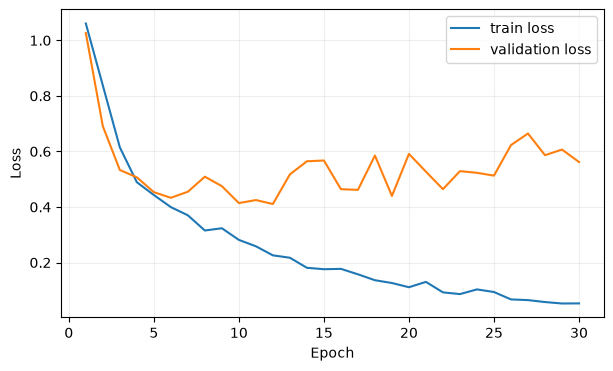

In [15]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [16]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


Best validation epoch: 17
Final test metrics:
  auc: 0.8356
  acc: 78.5000
  f1: 0.5115
  loss: 0.7026


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [17]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


Slide: patient_060_node_0
Predicted class: 3
Attention shape: (1, 1, 7171)
Attention sum for first slide: 0.9999998807907104


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


In [18]:
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)


# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

## Step 9a - Two proposals

**Proposal A (implemented, main extension): null-option attention (`method='null'`).** ABMIL's softmax forces the attention weights of every slide to sum to 1, even a slide with no tumour at all: the "mean embedding" of a normal slide is built exactly like that of a tumour slide. We borrow an idea from LLM attention (an explicit "attend to nothing" option, cf. attention sinks / softmax-one): add one extra logit `e_0 = b + log N` to the softmax, with a learnable scalar `b` (initialised to 0) and a **zero value vector**. Patches then get `a_i = softmax([e_0, e_1..e_N])_i`, so `z = sum_i a_i h_i = E * (usual weighted mean)` where `E = 1 - a_0` is the *evidence* (mass left for the patches) and `a_0` is the *null mass*. Why `log N`: it makes `a_0 = 1 / (1 + mean_j exp(e_j - b))` independent of the number of patches (slides have very different sizes). Cost: +1 parameter (164,996 vs 164,995 for C=2). The `log N` offset, `b=0` init and zero value vector were fixed **before any run**; nothing was tuned.

*Hypotheses (stated before running):* **H1** the null option improves C16 AUC/F1 (C16 has many normal slides); **H2** evidence `E` is higher on tumour slides than on normal ones (AUROC of `E` on C16, class means on C17/BRACS), and this is more than slide size (compare with `log N`; Spearman rho(E, log N)); **H3** any gain is not just a learned bias or lost normalisation: it must beat `null_fixed` (b frozen at 0) and `sigmoid` (a_i = sigmoid(e_i)/N, no competition at all).

*Novelty (hedged):* in a documented but **non-exhaustive** search of arXiv abstracts we found no WSI-MIL paper using a null option / sink / register; closest are ASMIL (normalised sigmoid + anchor), GCE-MIL and CAPRMIL (see the report). We therefore say "to our knowledge", never "first".

**Proposal B (implemented earlier, exploratory, negative): Focal-Mass Readout (FMR)** - a spatial readout (log of the largest box mass at radii 1, 4, 16 cells) added to ABMIL, with controls `fmr_shuffle` and `fmr_total`. It is reported in report Appendix A. A not-implemented CLAM-style instance loss is discussed in the report. A pseudo-bag ABMIL (simplified DTFD-MIL, `method='pbmil'`) is kept in Appendix B.

**Why A:** same optimiser, epochs and selection rule as the baseline, one extra parameter, built-in controls, and a diagnostic (null mass) that is interpretable. Code: `NullABMIL` in `mil_lib.py`; `run_null.sh` / `run_experiment.py` (see README). The cells below only display stored results; the full analysis is in `report/report.pdf`.


| Dataset | Method | #seeds | AUC (x100) | Acc (%) | F1 (x100) | best epoch |
|---|---|---|---|---|---|---|
| CAMELYON16 | abmil | 5 | 90.8 ± 5.0 | 87.1 ± 4.1 | 85.6 ± 4.7 | 2.6 |
| CAMELYON16 | abmil_rerun | 5 | 90.8 ± 5.0 | 87.1 ± 4.1 | 85.6 ± 4.7 | 2.6 |
| CAMELYON16 | null | 5 | 94.2 ± 2.2 | 91.5 ± 2.6 | 90.6 ± 3.1 | 5.4 |
| CAMELYON16 | null_fixed | 5 | 94.2 ± 2.2 | 91.5 ± 2.6 | 90.6 ± 3.1 | 5.4 |
| CAMELYON16 | sigmoid | 5 | 64.1 ± 5.5 | 67.3 ± 3.5 | 58.8 ± 4.3 | 17.0 |
| CAMELYON16 | null_nolog | 5 | 90.7 ± 5.1 | 87.1 ± 4.1 | 85.6 ± 4.7 | 2.6 |
| CAMELYON16 | null_val | 5 | 94.2 ± 2.2 | 91.5 ± 2.6 | 90.6 ± 3.1 | 5.4 |
| CAMELYON16 | null_valhi | 5 | 93.9 ± 2.4 | 89.3 ± 0.8 | 88.3 ± 0.9 | 4.8 |
| CAMELYON16 | null_k4val | 5 | 95.7 ± 1.2 | 92.2 ± 2.1 | 91.7 ± 2.3 | 8.0 |
| CAMELYON16 | fmr | 5 | 93.2 ± 2.9 | 90.4 ± 3.6 | 89.3 ± 4.0 | 2.4 |
| CAMELYON16 | fmr_shuffle | 5 | 93.2 ± 3.0 | 90.2 ± 3.5 | 89.1 ± 3.9 | 2.4 |
| CAMELYON16 | fmr_total | 5 | 92.7 ± 3.7 | 89.9 ± 3.7 | 88.8 ± 4.2 | 2.6 |
| CAMELYON16 | M5 | 5 | 90.1 ± 4.7 | 86.2 ± 2.9 | 84.6 ± 3.2 | 2.6 |
| CAMELYON16 | M2 | 3 | 90.9 ± 3.7 | 86.6 ± 3.2 | 84.9 ± 4.2 | 2.7 |
| CAMELYON16 | M10 | 3 | 88.3 ± 3.3 | 86.3 ± 1.6 | 84.8 ± 2.0 | 2.7 |
| CAMELYON16 | M5_nodetach | 3 | 91.6 ± 2.4 | 88.1 ± 3.8 | 87.0 ± 4.0 | 2.0 |
| CAMELYON17 | abmil | 5 | 84.0 ± 2.3 | 79.4 ± 2.1 | 56.3 ± 2.6 | 20.6 |
| CAMELYON17 | abmil_rerun | 5 | 85.4 ± 1.3 | 80.9 ± 2.9 | 53.2 ± 3.8 | 8.8 |
| CAMELYON17 | null | 5 | 87.0 ± 0.7 | 81.5 ± 1.6 | 59.3 ± 4.3 | 12.2 |
| CAMELYON17 | null_fixed | 5 | 87.0 ± 0.7 | 81.6 ± 1.6 | 59.4 ± 4.3 | 12.2 |
| CAMELYON17 | sigmoid | 5 | 72.0 ± 10.5 | 59.7 ± 5.7 | 33.4 ± 13.5 | 17.2 |
| CAMELYON17 | null_nolog | 5 | 84.8 ± 1.4 | 80.5 ± 1.4 | 53.6 ± 4.4 | 8.6 |
| CAMELYON17 | null_val | 5 | 87.0 ± 0.7 | 81.6 ± 1.6 | 59.4 ± 4.3 | 12.2 |
| CAMELYON17 | null_valhi | 5 | 88.0 ± 1.4 | 82.5 ± 2.1 | 56.4 ± 4.3 | 9.8 |
| CAMELYON17 | null_k4val | 5 | 87.1 ± 1.1 | 82.7 ± 1.9 | 62.5 ± 4.1 | 16.6 |
| CAMELYON17 | fmr | 5 | 84.7 ± 1.3 | 77.6 ± 2.2 | 53.0 ± 0.7 | 16.4 |
| CAMELYON17 | fmr_shuffle | 5 | 85.4 ± 0.8 | 76.4 ± 2.0 | 55.6 ± 1.4 | 16.2 |
| CAMELYON17 | fmr_total | 5 | 85.3 ± 1.8 | 79.2 ± 1.9 | 51.3 ± 4.3 | 11.0 |
| CAMELYON17 | M5 | 5 | 84.7 ± 2.1 | 80.4 ± 1.7 | 53.2 ± 2.8 | 19.6 |
| CAMELYON17 | M2 | 3 | 85.1 ± 1.9 | 80.8 ± 0.8 | 55.6 ± 2.8 | 15.7 |
| CAMELYON17 | M10 | 3 | 84.8 ± 3.5 | 80.8 ± 2.0 | 51.5 ± 4.3 | 18.0 |
| CAMELYON17 | M5_nodetach | 3 | 86.4 ± 1.1 | 83.2 ± 0.8 | 53.5 ± 4.3 | 6.7 |
| BRACS | abmil | 5 | 80.7 ± 0.8 | 39.8 ± 2.1 | 32.2 ± 3.2 | 6.0 |
| BRACS | abmil_rerun | 5 | 80.7 ± 0.8 | 39.8 ± 2.1 | 32.2 ± 3.2 | 6.0 |
| BRACS | null | 5 | 80.2 ± 0.9 | 41.4 ± 3.0 | 34.9 ± 3.4 | 8.4 |
| BRACS | null_fixed | 5 | 80.2 ± 0.9 | 41.4 ± 3.0 | 34.9 ± 3.4 | 8.4 |
| BRACS | sigmoid | 5 | 65.9 ± 0.5 | 33.5 ± 3.8 | 25.3 ± 5.5 | 21.4 |
| BRACS | null_nolog | 5 | 81.0 ± 0.9 | 40.7 ± 3.4 | 33.3 ± 3.5 | 5.4 |
| BRACS | null_val | 5 | 80.2 ± 0.9 | 41.4 ± 3.0 | 34.9 ± 3.4 | 8.4 |
| BRACS | null_valhi | 5 | 80.8 ± 0.5 | 42.6 ± 3.2 | 35.8 ± 3.7 | 8.2 |
| BRACS | null_k4val | 5 | 79.4 ± 1.0 | 41.4 ± 3.0 | 33.3 ± 1.7 | 6.8 |
| BRACS | fmr | 5 | 79.8 ± 1.4 | 42.1 ± 3.8 | 36.4 ± 4.6 | 9.2 |
| BRACS | fmr_shuffle | 5 | 80.5 ± 1.6 | 42.6 ± 4.7 | 35.8 ± 4.6 | 6.8 |
| BRACS | fmr_total | 5 | 79.9 ± 1.2 | 43.0 ± 3.4 | 34.9 ± 3.7 | 7.8 |
| BRACS | M5 | 5 | 80.7 ± 0.4 | 42.1 ± 3.5 | 35.6 ± 4.4 | 13.2 |
| BRACS | M2 | 3 | 79.7 ± 0.5 | 41.9 ± 4.0 | 35.4 ± 6.0 | 14.3 |
| BRACS | M10 | 3 | 81.3 ± 1.1 | 42.2 ± 2.9 | 35.0 ± 3.9 | 12.7 |
| BRACS | M5_nodetach | 3 | 81.0 ± 1.3 | 45.0 ± 3.4 | 38.1 ± 4.0 | 9.7 |

Paired comparison (same seed = same init & data order; same split). diff = method - reference:

| Dataset | Method | Reference | metric | mean diff | wins/seeds | paired t p-value |
|---|---|---|---|---|---|---|
| CAMELYON16 | abmil_rerun | abmil | AUC | +0.00 | 0/5 | nan |
| CAMELYON16 | abmil_rerun | abmil | Acc (%) | +0.00 | 0/5 | nan |
| CAMELYON16 | abmil_rerun | abmil | F1 | +0.00 | 0/5 | nan |
| CAMELYON16 | null | abmil | AUC | +3.46 | 4/5 | 0.140 |
| CAMELYON16 | null | abmil | Acc (%) | +4.34 | 4/5 | 0.135 |
| CAMELYON16 | null | abmil | F1 | +5.00 | 4/5 | 0.134 |
| CAMELYON16 | null_fixed | abmil | AUC | +3.43 | 4/5 | 0.143 |
| CAMELYON16 | null_fixed | abmil | Acc (%) | +4.34 | 4/5 | 0.135 |
| CAMELYON16 | null_fixed | abmil | F1 | +5.00 | 4/5 | 0.134 |
| CAMELYON16 | sigmoid | abmil | AUC | -26.72 | 0/5 | 0.001 |
| CAMELYON16 | sigmoid | abmil | Acc (%) | -19.84 | 0/5 | 0.002 |
| CAMELYON16 | sigmoid | abmil | F1 | -26.76 | 0/5 | 0.001 |
| CAMELYON16 | null_nolog | abmil | AUC | -0.03 | 1/5 | 0.305 |
| CAMELYON16 | null_nolog | abmil | Acc (%) | +0.00 | 0/5 | nan |
| CAMELYON16 | null_nolog | abmil | F1 | +0.00 | 0/5 | nan |
| CAMELYON16 | null_val | abmil | AUC | +3.43 | 4/5 | 0.145 |
| CAMELYON16 | null_val | abmil | Acc (%) | +4.34 | 4/5 | 0.135 |
| CAMELYON16 | null_val | abmil | F1 | +5.00 | 4/5 | 0.134 |
| CAMELYON16 | null_valhi | abmil | AUC | +3.08 | 5/5 | 0.072 |
| CAMELYON16 | null_valhi | abmil | Acc (%) | +2.17 | 3/5 | 0.231 |
| CAMELYON16 | null_valhi | abmil | F1 | +2.72 | 3/5 | 0.210 |
| CAMELYON16 | null_k4val | abmil | AUC | +4.89 | 4/5 | 0.068 |
| CAMELYON16 | null_k4val | abmil | Acc (%) | +5.12 | 5/5 | 0.014 |
| CAMELYON16 | null_k4val | abmil | F1 | +6.09 | 5/5 | 0.012 |
| CAMELYON16 | fmr | abmil | AUC | +2.42 | 3/5 | 0.286 |
| CAMELYON16 | fmr | abmil | Acc (%) | +3.26 | 4/5 | 0.254 |
| CAMELYON16 | fmr | abmil | F1 | +3.71 | 4/5 | 0.274 |
| CAMELYON16 | fmr_shuffle | abmil | AUC | +2.42 | 3/5 | 0.289 |
| CAMELYON16 | fmr_shuffle | abmil | Acc (%) | +3.10 | 4/5 | 0.270 |
| CAMELYON16 | fmr_shuffle | abmil | F1 | +3.53 | 4/5 | 0.291 |
| CAMELYON16 | fmr_total | abmil | AUC | +1.90 | 2/5 | 0.435 |
| CAMELYON16 | fmr_total | abmil | Acc (%) | +2.79 | 4/5 | 0.274 |
| CAMELYON16 | fmr_total | abmil | F1 | +3.17 | 4/5 | 0.299 |
| CAMELYON16 | M5 | abmil | AUC | -0.73 | 2/5 | 0.527 |
| CAMELYON16 | M5 | abmil | Acc (%) | -0.93 | 1/5 | 0.178 |
| CAMELYON16 | M5 | abmil | F1 | -0.97 | 1/5 | 0.243 |
| CAMELYON16 | M2 | abmil | AUC | -0.33 | 1/3 | 0.742 |
| CAMELYON16 | M2 | abmil | Acc (%) | -0.26 | 0/3 | 0.423 |
| CAMELYON16 | M2 | abmil | F1 | -0.21 | 1/3 | 0.565 |
| CAMELYON16 | M10 | abmil | AUC | -2.85 | 0/3 | 0.197 |
| CAMELYON16 | M10 | abmil | Acc (%) | -0.52 | 1/3 | 0.667 |
| CAMELYON16 | M10 | abmil | F1 | -0.34 | 1/3 | 0.829 |
| CAMELYON16 | M5_nodetach | abmil | AUC | +0.39 | 2/3 | 0.896 |
| CAMELYON16 | M5_nodetach | abmil | Acc (%) | +1.29 | 2/3 | 0.753 |
| CAMELYON16 | M5_nodetach | abmil | F1 | +1.85 | 2/3 | 0.688 |
| CAMELYON16 | abmil_rerun | abmil | AUC | +0.00 | 0/5 | nan |
| CAMELYON16 | abmil_rerun | abmil | Acc (%) | +0.00 | 0/5 | nan |
| CAMELYON16 | abmil_rerun | abmil | F1 | +0.00 | 0/5 | nan |
| CAMELYON16 | null | abmil_rerun | AUC | +3.46 | 4/5 | 0.140 |
| CAMELYON16 | null | abmil_rerun | Acc (%) | +4.34 | 4/5 | 0.135 |
| CAMELYON16 | null | abmil_rerun | F1 | +5.00 | 4/5 | 0.134 |
| CAMELYON16 | null | null_fixed | AUC | +0.03 | 4/5 | 0.189 |
| CAMELYON16 | null | null_fixed | Acc (%) | +0.00 | 0/5 | nan |
| CAMELYON16 | null | null_fixed | F1 | +0.00 | 0/5 | nan |
| CAMELYON16 | null | sigmoid | AUC | +30.18 | 5/5 | 0.001 |
| CAMELYON16 | null | sigmoid | Acc (%) | +24.19 | 5/5 | 0.000 |
| CAMELYON16 | null | sigmoid | F1 | +31.76 | 5/5 | 0.000 |
| CAMELYON16 | null_nolog | null | AUC | -3.49 | 1/5 | 0.140 |
| CAMELYON16 | null_nolog | null | Acc (%) | -4.34 | 1/5 | 0.135 |
| CAMELYON16 | null_nolog | null | F1 | -5.00 | 1/5 | 0.134 |
| CAMELYON16 | null_val | null | AUC | -0.03 | 1/5 | 0.178 |
| CAMELYON16 | null_val | null | Acc (%) | +0.00 | 0/5 | nan |
| CAMELYON16 | null_val | null | F1 | +0.00 | 0/5 | nan |
| CAMELYON16 | null_valhi | null | AUC | -0.38 | 2/5 | 0.714 |
| CAMELYON16 | null_valhi | null | Acc (%) | -2.17 | 1/5 | 0.154 |
| CAMELYON16 | null_valhi | null | F1 | -2.28 | 1/5 | 0.168 |
| CAMELYON16 | null_k4val | null | AUC | +1.43 | 4/5 | 0.193 |
| CAMELYON16 | null_k4val | null | Acc (%) | +0.78 | 3/5 | 0.582 |
| CAMELYON16 | null_k4val | null | F1 | +1.09 | 4/5 | 0.487 |
| CAMELYON16 | fmr | fmr_shuffle | AUC | -0.01 | 3/5 | 0.861 |
| CAMELYON16 | fmr | fmr_shuffle | Acc (%) | +0.16 | 1/5 | 0.374 |
| CAMELYON16 | fmr | fmr_shuffle | F1 | +0.18 | 1/5 | 0.374 |
| CAMELYON16 | fmr | fmr_total | AUC | +0.52 | 3/5 | 0.404 |
| CAMELYON16 | fmr | fmr_total | Acc (%) | +0.47 | 3/5 | 0.775 |
| CAMELYON16 | fmr | fmr_total | F1 | +0.54 | 3/5 | 0.777 |
| CAMELYON17 | abmil_rerun | abmil | AUC | +1.41 | 4/5 | 0.242 |
| CAMELYON17 | abmil_rerun | abmil | Acc (%) | +1.50 | 4/5 | 0.222 |
| CAMELYON17 | abmil_rerun | abmil | F1 | -3.05 | 1/5 | 0.291 |
| CAMELYON17 | null | abmil | AUC | +3.04 | 5/5 | 0.031 |
| CAMELYON17 | null | abmil | Acc (%) | +2.10 | 3/5 | 0.149 |
| CAMELYON17 | null | abmil | F1 | +3.08 | 3/5 | 0.300 |
| CAMELYON17 | null_fixed | abmil | AUC | +3.04 | 5/5 | 0.030 |
| CAMELYON17 | null_fixed | abmil | Acc (%) | +2.20 | 3/5 | 0.119 |
| CAMELYON17 | null_fixed | abmil | F1 | +3.17 | 3/5 | 0.282 |
| CAMELYON17 | sigmoid | abmil | AUC | -11.99 | 0/5 | 0.059 |
| CAMELYON17 | sigmoid | abmil | Acc (%) | -19.70 | 0/5 | 0.004 |
| CAMELYON17 | sigmoid | abmil | F1 | -22.89 | 0/5 | 0.022 |
| CAMELYON17 | null_nolog | abmil | AUC | +0.81 | 4/5 | 0.203 |
| CAMELYON17 | null_nolog | abmil | Acc (%) | +1.10 | 4/5 | 0.240 |
| CAMELYON17 | null_nolog | abmil | F1 | -2.63 | 1/5 | 0.216 |
| CAMELYON17 | null_val | abmil | AUC | +3.03 | 5/5 | 0.031 |
| CAMELYON17 | null_val | abmil | Acc (%) | +2.20 | 3/5 | 0.119 |
| CAMELYON17 | null_val | abmil | F1 | +3.17 | 3/5 | 0.282 |
| CAMELYON17 | null_valhi | abmil | AUC | +4.01 | 5/5 | 0.003 |
| CAMELYON17 | null_valhi | abmil | Acc (%) | +3.10 | 4/5 | 0.070 |
| CAMELYON17 | null_valhi | abmil | F1 | +0.12 | 2/5 | 0.966 |
| CAMELYON17 | null_k4val | abmil | AUC | +3.18 | 5/5 | 0.023 |
| CAMELYON17 | null_k4val | abmil | Acc (%) | +3.30 | 5/5 | 0.015 |
| CAMELYON17 | null_k4val | abmil | F1 | +6.26 | 4/5 | 0.032 |
| CAMELYON17 | fmr | abmil | AUC | +0.72 | 2/5 | 0.604 |
| CAMELYON17 | fmr | abmil | Acc (%) | -1.80 | 0/5 | 0.141 |
| CAMELYON17 | fmr | abmil | F1 | -3.23 | 0/5 | 0.057 |
| CAMELYON17 | fmr_shuffle | abmil | AUC | +1.45 | 4/5 | 0.172 |
| CAMELYON17 | fmr_shuffle | abmil | Acc (%) | -3.00 | 0/5 | 0.101 |
| CAMELYON17 | fmr_shuffle | abmil | F1 | -0.68 | 2/5 | 0.567 |
| CAMELYON17 | fmr_total | abmil | AUC | +1.36 | 4/5 | 0.222 |
| CAMELYON17 | fmr_total | abmil | Acc (%) | -0.20 | 1/5 | 0.704 |
| CAMELYON17 | fmr_total | abmil | F1 | -5.01 | 2/5 | 0.140 |
| CAMELYON17 | M5 | abmil | AUC | +0.74 | 4/5 | 0.172 |
| CAMELYON17 | M5 | abmil | Acc (%) | +1.00 | 3/5 | 0.357 |
| CAMELYON17 | M5 | abmil | F1 | -3.11 | 0/5 | 0.024 |
| CAMELYON17 | M2 | abmil | AUC | +0.99 | 3/3 | 0.194 |
| CAMELYON17 | M2 | abmil | Acc (%) | +0.67 | 2/3 | 0.604 |
| CAMELYON17 | M2 | abmil | F1 | -1.86 | 0/3 | 0.047 |
| CAMELYON17 | M10 | abmil | AUC | +0.75 | 2/3 | 0.262 |
| CAMELYON17 | M10 | abmil | Acc (%) | +0.67 | 2/3 | 0.456 |
| CAMELYON17 | M10 | abmil | F1 | -5.95 | 0/3 | 0.036 |
| CAMELYON17 | M5_nodetach | abmil | AUC | +2.31 | 3/3 | 0.390 |
| CAMELYON17 | M5_nodetach | abmil | Acc (%) | +3.00 | 2/3 | 0.188 |
| CAMELYON17 | M5_nodetach | abmil | F1 | -3.98 | 1/3 | 0.408 |
| CAMELYON17 | abmil_rerun | abmil | AUC | +1.41 | 4/5 | 0.242 |
| CAMELYON17 | abmil_rerun | abmil | Acc (%) | +1.50 | 4/5 | 0.222 |
| CAMELYON17 | abmil_rerun | abmil | F1 | -3.05 | 1/5 | 0.291 |
| CAMELYON17 | null | abmil_rerun | AUC | +1.63 | 5/5 | 0.012 |
| CAMELYON17 | null | abmil_rerun | Acc (%) | +0.60 | 2/5 | 0.668 |
| CAMELYON17 | null | abmil_rerun | F1 | +6.13 | 5/5 | 0.037 |
| CAMELYON17 | null | null_fixed | AUC | -0.00 | 1/5 | 0.687 |
| CAMELYON17 | null | null_fixed | Acc (%) | -0.10 | 0/5 | 0.374 |
| CAMELYON17 | null | null_fixed | F1 | -0.09 | 0/5 | 0.374 |
| CAMELYON17 | null | sigmoid | AUC | +15.03 | 5/5 | 0.033 |
| CAMELYON17 | null | sigmoid | Acc (%) | +21.80 | 5/5 | 0.001 |
| CAMELYON17 | null | sigmoid | F1 | +25.97 | 5/5 | 0.016 |
| CAMELYON17 | null_nolog | null | AUC | -2.22 | 0/5 | 0.012 |
| CAMELYON17 | null_nolog | null | Acc (%) | -1.00 | 1/5 | 0.240 |
| CAMELYON17 | null_nolog | null | F1 | -5.71 | 1/5 | 0.089 |
| CAMELYON17 | null_val | null | AUC | -0.01 | 3/5 | 0.532 |
| CAMELYON17 | null_val | null | Acc (%) | +0.10 | 1/5 | 0.374 |
| CAMELYON17 | null_val | null | F1 | +0.09 | 1/5 | 0.374 |
| CAMELYON17 | null_valhi | null | AUC | +0.97 | 4/5 | 0.235 |
| CAMELYON17 | null_valhi | null | Acc (%) | +1.00 | 3/5 | 0.576 |
| CAMELYON17 | null_valhi | null | F1 | -2.96 | 1/5 | 0.115 |
| CAMELYON17 | null_k4val | null | AUC | +0.15 | 3/5 | 0.769 |
| CAMELYON17 | null_k4val | null | Acc (%) | +1.20 | 3/5 | 0.294 |
| CAMELYON17 | null_k4val | null | F1 | +3.18 | 3/5 | 0.253 |
| CAMELYON17 | fmr | fmr_shuffle | AUC | -0.73 | 2/5 | 0.164 |
| CAMELYON17 | fmr | fmr_shuffle | Acc (%) | +1.20 | 3/5 | 0.521 |
| CAMELYON17 | fmr | fmr_shuffle | F1 | -2.56 | 0/5 | 0.019 |
| CAMELYON17 | fmr | fmr_total | AUC | -0.64 | 1/5 | 0.330 |
| CAMELYON17 | fmr | fmr_total | Acc (%) | -1.60 | 1/5 | 0.173 |
| CAMELYON17 | fmr | fmr_total | F1 | +1.77 | 3/5 | 0.384 |
| BRACS | abmil_rerun | abmil | AUC | +0.00 | 0/5 | nan |
| BRACS | abmil_rerun | abmil | Acc (%) | +0.00 | 0/5 | nan |
| BRACS | abmil_rerun | abmil | F1 | +0.00 | 0/5 | nan |
| BRACS | null | abmil | AUC | -0.46 | 0/5 | 0.039 |
| BRACS | null | abmil | Acc (%) | +1.63 | 3/5 | 0.245 |
| BRACS | null | abmil | F1 | +2.68 | 4/5 | 0.189 |
| BRACS | null_fixed | abmil | AUC | -0.48 | 0/5 | 0.041 |
| BRACS | null_fixed | abmil | Acc (%) | +1.63 | 3/5 | 0.245 |
| BRACS | null_fixed | abmil | F1 | +2.68 | 4/5 | 0.189 |
| BRACS | sigmoid | abmil | AUC | -14.80 | 0/5 | 0.000 |
| BRACS | sigmoid | abmil | Acc (%) | -6.28 | 0/5 | 0.010 |
| BRACS | sigmoid | abmil | F1 | -6.94 | 0/5 | 0.037 |
| BRACS | null_nolog | abmil | AUC | +0.30 | 3/5 | 0.398 |
| BRACS | null_nolog | abmil | Acc (%) | +0.93 | 2/5 | 0.242 |
| BRACS | null_nolog | abmil | F1 | +1.12 | 2/5 | 0.285 |
| BRACS | null_val | abmil | AUC | -0.47 | 0/5 | 0.041 |
| BRACS | null_val | abmil | Acc (%) | +1.63 | 3/5 | 0.245 |
| BRACS | null_val | abmil | F1 | +2.68 | 4/5 | 0.189 |
| BRACS | null_valhi | abmil | AUC | +0.12 | 2/5 | 0.690 |
| BRACS | null_valhi | abmil | Acc (%) | +2.79 | 3/5 | 0.208 |
| BRACS | null_valhi | abmil | F1 | +3.63 | 4/5 | 0.241 |
| BRACS | null_k4val | abmil | AUC | -1.27 | 0/5 | 0.045 |
| BRACS | null_k4val | abmil | Acc (%) | +1.63 | 3/5 | 0.245 |
| BRACS | null_k4val | abmil | F1 | +1.10 | 3/5 | 0.519 |
| BRACS | fmr | abmil | AUC | -0.94 | 1/5 | 0.237 |
| BRACS | fmr | abmil | Acc (%) | +2.33 | 3/5 | 0.333 |
| BRACS | fmr | abmil | F1 | +4.15 | 4/5 | 0.267 |
| BRACS | fmr_shuffle | abmil | AUC | -0.20 | 2/5 | 0.617 |
| BRACS | fmr_shuffle | abmil | Acc (%) | +2.79 | 3/5 | 0.329 |
| BRACS | fmr_shuffle | abmil | F1 | +3.57 | 4/5 | 0.323 |
| BRACS | fmr_total | abmil | AUC | -0.76 | 2/5 | 0.132 |
| BRACS | fmr_total | abmil | Acc (%) | +3.26 | 5/5 | 0.038 |
| BRACS | fmr_total | abmil | F1 | +2.66 | 3/5 | 0.321 |
| BRACS | M5 | abmil | AUC | +0.01 | 2/5 | 0.978 |
| BRACS | M5 | abmil | Acc (%) | +2.33 | 3/5 | 0.374 |
| BRACS | M5 | abmil | F1 | +3.37 | 3/5 | 0.244 |
| BRACS | M2 | abmil | AUC | -0.42 | 0/3 | 0.068 |
| BRACS | M2 | abmil | Acc (%) | +2.33 | 2/3 | 0.580 |
| BRACS | M2 | abmil | F1 | +3.21 | 2/3 | 0.438 |
| BRACS | M10 | abmil | AUC | +1.19 | 2/3 | 0.265 |
| BRACS | M10 | abmil | Acc (%) | +2.71 | 1/3 | 0.423 |
| BRACS | M10 | abmil | F1 | +2.74 | 2/3 | 0.471 |
| BRACS | M5_nodetach | abmil | AUC | +0.89 | 2/3 | 0.427 |
| BRACS | M5_nodetach | abmil | Acc (%) | +5.43 | 3/3 | 0.229 |
| BRACS | M5_nodetach | abmil | F1 | +5.92 | 3/3 | 0.112 |
| BRACS | abmil_rerun | abmil | AUC | +0.00 | 0/5 | nan |
| BRACS | abmil_rerun | abmil | Acc (%) | +0.00 | 0/5 | nan |
| BRACS | abmil_rerun | abmil | F1 | +0.00 | 0/5 | nan |
| BRACS | null | abmil_rerun | AUC | -0.46 | 0/5 | 0.039 |
| BRACS | null | abmil_rerun | Acc (%) | +1.63 | 3/5 | 0.245 |
| BRACS | null | abmil_rerun | F1 | +2.68 | 4/5 | 0.189 |
| BRACS | null | null_fixed | AUC | +0.01 | 3/5 | 0.147 |
| BRACS | null | null_fixed | Acc (%) | +0.00 | 0/5 | nan |
| BRACS | null | null_fixed | F1 | +0.00 | 0/5 | nan |
| BRACS | null | sigmoid | AUC | +14.33 | 5/5 | 0.000 |
| BRACS | null | sigmoid | Acc (%) | +7.91 | 5/5 | 0.002 |
| BRACS | null | sigmoid | F1 | +9.61 | 5/5 | 0.001 |
| BRACS | null_nolog | null | AUC | +0.77 | 5/5 | 0.038 |
| BRACS | null_nolog | null | Acc (%) | -0.70 | 2/5 | 0.683 |
| BRACS | null_nolog | null | F1 | -1.55 | 2/5 | 0.401 |
| BRACS | null_val | null | AUC | -0.00 | 3/5 | 0.894 |
| BRACS | null_val | null | Acc (%) | +0.00 | 0/5 | nan |
| BRACS | null_val | null | F1 | +0.00 | 0/5 | nan |
| BRACS | null_valhi | null | AUC | +0.58 | 4/5 | 0.187 |
| BRACS | null_valhi | null | Acc (%) | +1.16 | 3/5 | 0.430 |
| BRACS | null_valhi | null | F1 | +0.96 | 3/5 | 0.561 |
| BRACS | null_k4val | null | AUC | -0.80 | 0/5 | 0.173 |
| BRACS | null_k4val | null | Acc (%) | +0.00 | 0/5 | nan |
| BRACS | null_k4val | null | F1 | -1.58 | 0/5 | 0.141 |
| BRACS | fmr | fmr_shuffle | AUC | -0.73 | 1/5 | 0.467 |
| BRACS | fmr | fmr_shuffle | Acc (%) | -0.47 | 0/5 | 0.374 |
| BRACS | fmr | fmr_shuffle | F1 | +0.58 | 1/5 | 0.389 |
| BRACS | fmr | fmr_total | AUC | -0.18 | 3/5 | 0.775 |
| BRACS | fmr | fmr_total | Acc (%) | -0.93 | 2/5 | 0.684 |
| BRACS | fmr | fmr_total | F1 | +1.49 | 2/5 | 0.423 |


### Part 1: evidence (1 - null mass) on test slides

| Dataset | Model | learned b | mean evidence | evidence range (min–max, mean over seeds) | evidence by class | ρ(evidence, log N) | AUROC evidence | AUROC log N |
|---|---|---|---|---|---|---|---|---|
| C16 | null | -0.02 | 0.631 ± 0.098 | 0.33–1.00 | c0=0.50, c1=0.84 | 0.251 ± 0.073 | 0.947 ± 0.017 | 0.644 ± 0.000 |
| C16 | null_fixed | 0.00 | 0.629 ± 0.098 | 0.33–1.00 | c0=0.50, c1=0.84 | 0.252 ± 0.072 | 0.947 ± 0.017 | 0.644 ± 0.000 |
| C16 | sigmoid | 0.00 | 0.522 ± 0.052 | 0.26–0.94 | c0=0.51, c1=0.54 | -0.145 ± 0.118 | 0.540 ± 0.027 | 0.644 ± 0.000 |
| C17 | null | -0.02 | 0.869 ± 0.041 | 0.54–1.00 | c0=0.81, c1=0.85, c2=0.95, c3=1.00 | 0.038 ± 0.028 | – | – |
| C17 | null_fixed | 0.00 | 0.868 ± 0.041 | 0.54–1.00 | c0=0.81, c1=0.84, c2=0.95, c3=1.00 | 0.038 ± 0.028 | – | – |
| C17 | sigmoid | 0.00 | 0.822 ± 0.236 | 0.80–0.84 | c0=0.82, c1=0.82, c2=0.82, c3=0.82 | -0.030 ± 0.188 | – | – |
| BRACS | null | -0.03 | 0.943 ± 0.019 | 0.66–1.00 | c0=0.82, c1=0.89, c2=0.92, c3=0.95, c4=0.97, c5=0.97, c6=1.00 | 0.115 ± 0.012 | – | – |
| BRACS | null_fixed | 0.00 | 0.942 ± 0.019 | 0.66–1.00 | c0=0.82, c1=0.89, c2=0.92, c3=0.95, c4=0.97, c5=0.97, c6=1.00 | 0.115 ± 0.012 | – | – |
| BRACS | sigmoid | 0.00 | 0.993 ± 0.008 | 0.97–1.00 | c0=0.99, c1=0.99, c2=0.99, c3=0.99, c4=0.99, c5=0.99, c6=1.00 | -0.117 ± 0.075 | – | – |

### Part 2: attention vs pathologist contours on C16 test_068

| Model | Attention AUROC | Top-5% precision | Attention mass in tumour (renormalised) | Evidence on this slide |
|---|---|---|---|---|
| abmil | 0.963 ± 0.023 | 0.738 ± 0.036 | 0.971 ± 0.018 | 1.000 ± 0.000 |
| null | 0.975 ± 0.013 | 0.767 ± 0.015 | 0.965 ± 0.009 | 0.984 ± 0.005 |
| null_fixed | 0.975 ± 0.013 | 0.767 ± 0.015 | 0.965 ± 0.009 | 0.983 ± 0.005 |
| sigmoid | 0.957 ± 0.014 | 0.720 ± 0.017 | 0.062 ± 0.006 | 0.644 ± 0.060 |

Chance (tumour fraction) = 0.041


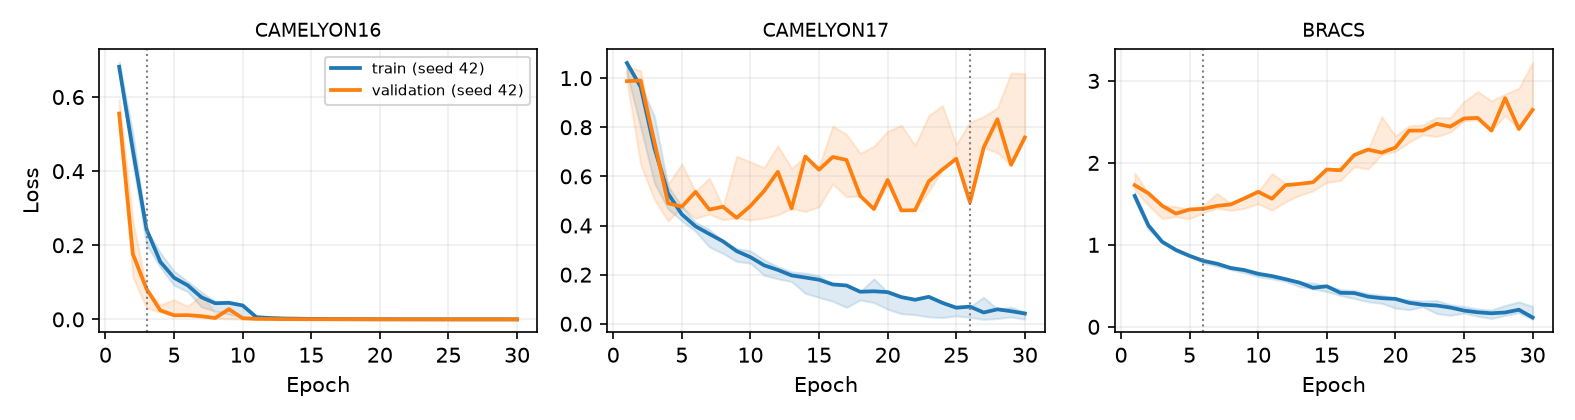

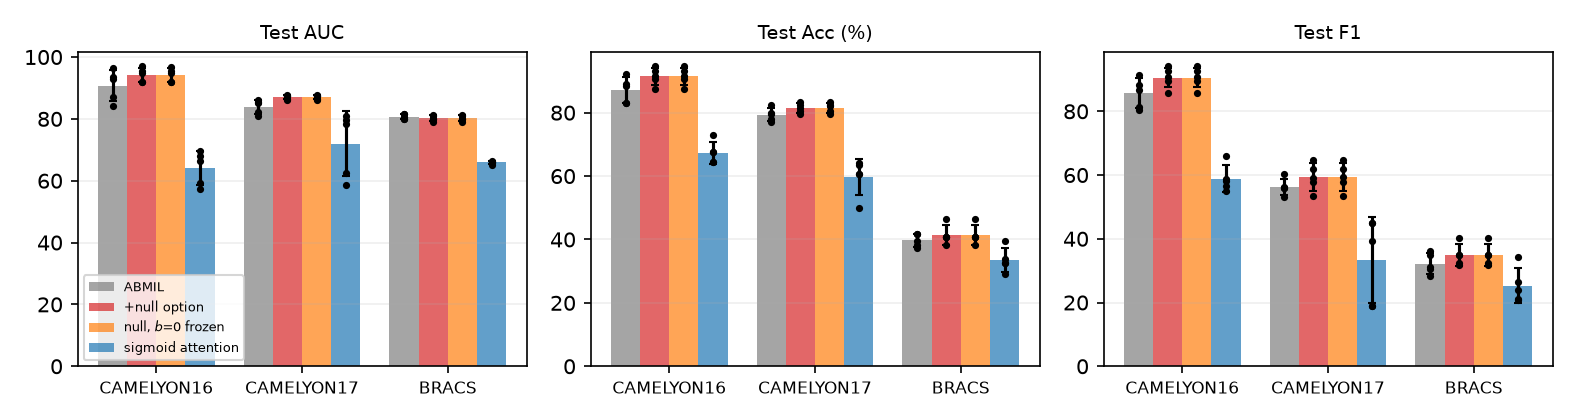

In [19]:
# Display the stored multi-seed results of the baseline and the extension
# (produced by run_experiment.py / run_null.sh / analyze_results.py / null_diagnostic.py; 5 seeds per dataset).
from pathlib import Path
from IPython.display import Markdown, Image, display
res = Path(PROJECT_DIR) / 'results' if 'PROJECT_DIR' in globals() else Path('results')
display(Markdown((res / 'summary.md').read_text()))
display(Markdown((res / 'null_diagnostic.md').read_text()))
for name in ['loss_curves_baseline', 'test_metrics_bar']:
    display(Image(filename=str(Path(res.parent) / 'report' / 'figs' / f'{name}.png')))


## Step 9b - Analysis

* **Baseline (5 seeds, test).** AUC 90.8 / 84.0 / 80.7 and macro-F1 85.6 / 56.3 / 32.2 on C16 / C17 / BRACS. C16 variance is large (std about 5 points), BRACS (7 classes) is hard (accuracy about 40%, chance 14%).
* **H1 - does the null option help? Partly, weakly.** Null vs ABMIL (5 seeds, AUC / F1): C16 94.2 vs 90.8 / 90.6 vs 85.6 (paired dAUC +3.5, p=.14); C17 87.0 vs 84.0 / 59.3 vs 56.3 (dAUC +3.0, p=.031, better in 5/5 seeds); BRACS 80.2 vs 80.7 / 34.9 vs 32.2 (dAUC -0.5, p=.039, i.e. slightly worse AUC). The direction on C16 agrees with H1, but it is not statistically established. Of the 18 tests of null / frozen-null vs ABMIL, 4 have uncorrected p<.05 (about 1 expected by chance), so these are weak evidence. The best epoch also moves (C16: 5.4 vs 2.6), so part of the gain may come from smoother optimisation / model selection; we did not separate this.
* **H2 - is the null mass meaningful? Yes on C16.** Evidence `E = 1 - a_0` is 0.50 for normal and 0.84 for tumour test slides; `E` alone has AUROC 0.947 +- 0.017 (the model's own AUC is 94.2). `log N` alone gives only 0.644 and Spearman rho(E, log N) = 0.25, so it is not just bag size. On C17 / BRACS mean `E` rises with the class index (0.81 -> 1.00; 0.82 -> 1.00) with weak correlation to `log N` (0.04, 0.11); class-index meaning is unverified. Caveat: `E` is trained jointly with the classifier.
* **H3 - learned bias or lost normalisation? Neither is shown to matter.** `null_fixed` (b frozen at 0) equals the learned null (identical Acc/F1 on C16 and BRACS; no p<.05 anywhere; learned b only reaches about -0.02), so the learned parameter is superfluous - the effect comes from the fixed `log N` null competitor. `sigmoid` (no competition) is much worse (AUC 64.1 / 72.0 / 65.9; all 9 tests vs null p<.05), but this control is untuned, trains slowly and gives near-uniform attention (6% of mass in the tumour on `test_068`), so it shows only that unnormalised attention is not a drop-in replacement, not that softmax competition is essential.
* **Attention check (C16 `test_068`, one slide).** Patch-level AUROC 0.975 +- 0.013 (null) vs 0.963 +- 0.023 (ABMIL); top-5% precision 0.767 vs 0.738; mass in tumour 96.5% vs 97.1%. Within one-slide noise: the null option does not degrade localisation. Evidence on that slide is 0.984.
* **Exploratory, earlier (appendices).** Focal-Mass Readout was negative: its C16 gain (+2.4 AUC) is reproduced by the shuffled-coordinate control, F1 on C17 is lower (-3.2, p=.057), and permuting coordinates at test time changes no AUC (the models do not use the geometry). Pseudo-bag ABMIL is neutral (macro-F1 on C17 -3.1, p=.024 uncorrected).
* **Limitations.** Tiny validation sets drive model selection; five seeds; uncorrected tests (45 for null and controls); the `log N` offset, zero value vector and initialisation were fixed in advance (the offset and the value are ablated in Step 9c, the initialisation is not); frozen encoder supplied by the course; patch grid inferred from coordinates (512-px bins) and unverified; the novelty statement rests on a non-exhaustive arXiv-abstract search ("to our knowledge", never "first"). See report Sec. VIII.

Note: numbers in this notebook (seed 42, uncached loader) can differ slightly from the scripted multi-seed runs.


## Step 9c - Follow-up study: which part matters, is the null mass an abstention score, and robustness to bag size

Pre-registered in `PREREG_mechanism.md` (one amendment, H-A3, was written after seeing results). The cells below only display stored results (`run_mech.sh`, `abstain_robust.py`); the analysis is in report Sec. VII.

* **A - mechanism ablation (test AUC x100, 5 seeds).** `null_nolog` (no `log N` offset) is about as good as ABMIL (C16 90.7, C17 84.8, BRACS 81.0) and worse than the null model on C16/C17, so the bag-size-scaled competitor is the ingredient that matters. A learned null value (`null_val`, `null_valhi`) and four nulls with values (`null_k4val`) give no significant gain (all p >= .17, uncorrected). *Why `log N` matters:* without it the null logit is a constant, so the null mass is about 1/N for large N and the null entry is almost never used.
* **B - is `E = 1 - a_0` an error detector? No.** AUROC for errors is 0.44 (C16) and 0.43 (C17) for `E`, i.e. chance or worse, against 0.78 / 0.72 for the max-softmax probability (0.67 vs 0.70 on BRACS). `E` measures how much of the slide looks like evidence (a property of the slide), whereas confidence is a property of the decision.
* **C - fewer patches per slide.** Randomly keeping 5% of the patches costs ABMIL 11.2 / 2.9 / 1.9 AUC and the null model 13.3 / 5.2 / 1.1 (C16 / C17 / BRACS): the hypothesis that the null model degrades more gracefully is **not** supported on C16 and C17.
* **Caveats.** C17 ABMIL is not bit-reproducible (84.0 first run, 85.4 repeat), so C17 differences below about 1.4 AUC are within noise; p-values are uncorrected; the novelty of A/B/C was not searched exhaustively.


In [20]:
# Display the stored follow-up results (A: mechanism ablation rows in summary.md; B and C: abstain_robust.md)
display(Markdown((res / 'abstain_robust.md').read_text()))


# Extension B/C: abstention and bag-size robustness

## B. Error detection / selective prediction (test set, mean±std over seeds)

| Dataset | Model | Score | err rate | AUROC(err) | AURC↓ | risk@80%cov | risk@50%cov |
|---|---|---|---|---|---|---|---|
| C16 | abmil | MSP | 0.129±0.041 | 0.784±0.053 | 0.050±0.029 | 0.081±0.043 | 0.052±0.030 |
| C16 | null | MSP | 0.085±0.026 | 0.785±0.062 | 0.029±0.013 | 0.050±0.014 | 0.022±0.018 |
| C16 | null | E | 0.085±0.026 | 0.436±0.038 | 0.075±0.028 | 0.106±0.033 | 0.120±0.048 |
| C16 | null_fixed | MSP | 0.085±0.026 | 0.783±0.061 | 0.029±0.013 | 0.050±0.014 | 0.022±0.018 |
| C16 | null_fixed | E | 0.085±0.026 | 0.437±0.037 | 0.075±0.028 | 0.106±0.033 | 0.120±0.048 |
| C16 | null_nolog | MSP | 0.129±0.041 | 0.782±0.054 | 0.050±0.029 | 0.081±0.043 | 0.049±0.033 |
| C16 | null_nolog | E | 0.129±0.041 | 0.459±0.036 | 0.111±0.033 | 0.144±0.047 | 0.151±0.035 |
| C16 | null_val | MSP | 0.085±0.026 | 0.784±0.061 | 0.029±0.013 | 0.050±0.014 | 0.022±0.018 |
| C16 | null_val | E | 0.085±0.026 | 0.435±0.038 | 0.076±0.028 | 0.106±0.033 | 0.120±0.048 |
| C16 | null_valhi | MSP | 0.107±0.008 | 0.811±0.058 | 0.034±0.012 | 0.054±0.011 | 0.028±0.020 |
| C16 | null_valhi | E | 0.107±0.008 | 0.429±0.041 | 0.097±0.009 | 0.127±0.011 | 0.138±0.022 |
| C16 | null_k4val | MSP | 0.078±0.021 | 0.816±0.054 | 0.021±0.007 | 0.035±0.009 | 0.009±0.008 |
| C16 | null_k4val | E | 0.078±0.021 | 0.417±0.027 | 0.072±0.022 | 0.094±0.025 | 0.117±0.028 |
| C17 | abmil | MSP | 0.191±0.029 | 0.733±0.018 | 0.100±0.021 | 0.129±0.020 | 0.092±0.008 |
| C17 | null | MSP | 0.185±0.016 | 0.722±0.031 | 0.098±0.008 | 0.120±0.017 | 0.102±0.018 |
| C17 | null | E | 0.185±0.016 | 0.435±0.039 | 0.170±0.017 | 0.209±0.017 | 0.252±0.026 |
| C17 | null_fixed | MSP | 0.184±0.016 | 0.720±0.028 | 0.098±0.008 | 0.120±0.017 | 0.102±0.018 |
| C17 | null_fixed | E | 0.184±0.016 | 0.435±0.039 | 0.169±0.017 | 0.206±0.016 | 0.250±0.026 |
| C17 | null_nolog | MSP | 0.195±0.014 | 0.730±0.027 | 0.105±0.010 | 0.128±0.009 | 0.096±0.015 |
| C17 | null_nolog | E | 0.195±0.014 | 0.400±0.018 | 0.191±0.015 | 0.226±0.016 | 0.282±0.041 |
| C17 | null_val | MSP | 0.184±0.016 | 0.719±0.028 | 0.098±0.008 | 0.120±0.017 | 0.102±0.018 |
| C17 | null_val | E | 0.184±0.016 | 0.435±0.039 | 0.169±0.018 | 0.208±0.017 | 0.248±0.026 |
| C17 | null_valhi | MSP | 0.175±0.021 | 0.725±0.048 | 0.089±0.017 | 0.113±0.025 | 0.090±0.029 |
| C17 | null_valhi | E | 0.175±0.021 | 0.437±0.035 | 0.162±0.026 | 0.191±0.029 | 0.236±0.042 |
| C17 | null_k4val | MSP | 0.173±0.019 | 0.706±0.028 | 0.096±0.008 | 0.120±0.007 | 0.092±0.013 |
| C17 | null_k4val | E | 0.173±0.019 | 0.453±0.035 | 0.157±0.026 | 0.190±0.025 | 0.218±0.043 |
| BRACS | abmil | MSP | 0.602±0.021 | 0.738±0.045 | 0.374±0.020 | 0.571±0.017 | 0.456±0.042 |
| BRACS | null | MSP | 0.586±0.030 | 0.703±0.038 | 0.379±0.012 | 0.562±0.021 | 0.484±0.019 |
| BRACS | null | E | 0.586±0.030 | 0.670±0.026 | 0.415±0.035 | 0.562±0.035 | 0.488±0.033 |
| BRACS | null_fixed | MSP | 0.586±0.030 | 0.703±0.037 | 0.379±0.012 | 0.562±0.021 | 0.484±0.019 |
| BRACS | null_fixed | E | 0.586±0.030 | 0.670±0.025 | 0.416±0.035 | 0.562±0.035 | 0.488±0.033 |
| BRACS | null_nolog | MSP | 0.593±0.034 | 0.731±0.050 | 0.368±0.027 | 0.568±0.026 | 0.456±0.045 |
| BRACS | null_nolog | E | 0.593±0.034 | 0.701±0.054 | 0.407±0.062 | 0.557±0.054 | 0.460±0.080 |
| BRACS | null_val | MSP | 0.586±0.030 | 0.703±0.038 | 0.379±0.012 | 0.562±0.021 | 0.484±0.019 |
| BRACS | null_val | E | 0.586±0.030 | 0.670±0.026 | 0.416±0.035 | 0.562±0.035 | 0.488±0.033 |
| BRACS | null_valhi | MSP | 0.574±0.032 | 0.708±0.032 | 0.367±0.021 | 0.545±0.039 | 0.442±0.037 |
| BRACS | null_valhi | E | 0.574±0.032 | 0.666±0.055 | 0.408±0.054 | 0.557±0.032 | 0.474±0.051 |
| BRACS | null_k4val | MSP | 0.586±0.030 | 0.722±0.010 | 0.370±0.034 | 0.557±0.033 | 0.451±0.048 |
| BRACS | null_k4val | E | 0.586±0.030 | 0.670±0.017 | 0.414±0.046 | 0.562±0.035 | 0.502±0.027 |

## C. Test-time patch subsampling: AUC (macro) / acc % / mean evidence E

| Dataset | Model | 100% | 50% | 25% | 10% | 5% |
|---|---|---|---|---|---|---|
| C16 | abmil | 0.908±0.050 / 87.132±4.087 / E=– | 0.887±0.051 / 85.457±3.065 / E=– | 0.866±0.050 / 83.845±2.759 / E=– | 0.823±0.050 / 81.829±1.871 / E=– | 0.796±0.050 / 79.752±2.085 / E=– |
| C16 | null | 0.942±0.022 / 91.473±2.629 / E=0.631±0.098 | 0.923±0.023 / 89.240±1.907 / E=0.627±0.099 | 0.893±0.022 / 87.969±1.537 / E=0.624±0.100 | 0.844±0.025 / 84.217±1.375 / E=0.613±0.101 | 0.810±0.027 / 82.140±1.037 / E=0.600±0.101 |
| C16 | null_fixed | 0.942±0.022 / 91.473±2.629 / E=0.629±0.098 | 0.923±0.023 / 89.209±1.913 / E=0.625±0.099 | 0.893±0.022 / 87.969±1.537 / E=0.622±0.099 | 0.844±0.025 / 84.217±1.375 / E=0.611±0.100 | 0.809±0.027 / 82.109±1.083 / E=0.599±0.101 |
| C16 | null_nolog | 0.907±0.051 / 87.132±4.087 / E=0.995±0.003 | 0.886±0.051 / 85.519±3.008 / E=0.990±0.005 | 0.861±0.048 / 83.907±2.862 / E=0.981±0.010 | 0.811±0.046 / 81.798±1.836 / E=0.956±0.024 | 0.776±0.042 / 79.690±1.998 / E=0.918±0.041 |
| C16 | null_val | 0.942±0.022 / 91.473±2.629 / E=0.627±0.099 | 0.923±0.023 / 89.178±1.922 / E=0.623±0.100 | 0.893±0.023 / 88.000±1.572 / E=0.619±0.100 | 0.844±0.025 / 84.279±1.336 / E=0.608±0.101 | 0.809±0.027 / 82.171±1.091 / E=0.596±0.102 |
| C16 | null_valhi | 0.939±0.024 / 89.302±0.849 / E=0.456±0.083 | 0.915±0.024 / 88.000±1.204 / E=0.450±0.083 | 0.881±0.023 / 86.078±1.505 / E=0.445±0.084 | 0.832±0.027 / 82.946±1.235 / E=0.427±0.084 | 0.805±0.025 / 80.992±0.626 / E=0.409±0.083 |
| C16 | null_k4val | 0.957±0.012 / 92.248±2.123 / E=0.643±0.063 | 0.940±0.015 / 89.612±1.864 / E=0.639±0.064 | 0.908±0.014 / 88.651±1.682 / E=0.635±0.065 | 0.861±0.015 / 84.713±1.525 / E=0.622±0.067 | 0.826±0.013 / 82.791±0.937 / E=0.608±0.068 |
| C17 | abmil | 0.854±0.013 / 80.900±2.945 / E=– | 0.851±0.009 / 80.860±3.015 / E=– | 0.851±0.007 / 80.620±2.846 / E=– | 0.839±0.004 / 80.480±2.095 / E=– | 0.825±0.003 / 80.640±2.032 / E=– |
| C17 | null | 0.870±0.007 / 81.500±1.581 / E=0.869±0.041 | 0.860±0.008 / 81.280±1.169 / E=0.868±0.041 | 0.850±0.006 / 80.460±1.363 / E=0.867±0.042 | 0.834±0.007 / 80.120±1.711 / E=0.865±0.042 | 0.818±0.006 / 79.700±0.957 / E=0.861±0.043 |
| C17 | null_fixed | 0.870±0.007 / 81.600±1.597 / E=0.868±0.041 | 0.860±0.008 / 81.260±1.203 / E=0.868±0.041 | 0.850±0.006 / 80.480±1.283 / E=0.866±0.042 | 0.834±0.007 / 80.180±1.708 / E=0.864±0.042 | 0.818±0.006 / 79.680±0.991 / E=0.861±0.043 |
| C17 | null_nolog | 0.848±0.014 / 80.500±1.369 / E=0.996±0.001 | 0.844±0.010 / 80.580±1.258 / E=0.992±0.002 | 0.846±0.007 / 80.480±1.370 / E=0.985±0.003 | 0.833±0.005 / 79.720±1.244 / E=0.963±0.008 | 0.816±0.007 / 79.780±1.184 / E=0.931±0.014 |
| C17 | null_val | 0.870±0.007 / 81.600±1.597 / E=0.868±0.042 | 0.860±0.008 / 81.260±1.278 / E=0.868±0.042 | 0.850±0.006 / 80.460±1.299 / E=0.866±0.042 | 0.834±0.007 / 80.120±1.754 / E=0.864±0.043 | 0.818±0.006 / 79.720±0.884 / E=0.861±0.043 |
| C17 | null_valhi | 0.880±0.014 / 82.500±2.121 / E=0.739±0.067 | 0.869±0.018 / 82.300±2.218 / E=0.737±0.068 | 0.861±0.019 / 81.880±2.724 / E=0.735±0.068 | 0.846±0.018 / 80.760±2.780 / E=0.731±0.069 | 0.830±0.020 / 80.660±2.268 / E=0.726±0.070 |
| C17 | null_k4val | 0.871±0.011 / 82.700±1.857 / E=0.873±0.046 | 0.861±0.012 / 82.760±1.469 / E=0.872±0.046 | 0.851±0.014 / 81.920±1.397 / E=0.871±0.046 | 0.832±0.014 / 81.320±1.460 / E=0.869±0.046 | 0.814±0.015 / 80.180±1.085 / E=0.866±0.045 |
| BRACS | abmil | 0.807±0.008 / 39.767±2.080 / E=– | 0.808±0.008 / 41.256±1.591 / E=– | 0.801±0.008 / 40.140±1.322 / E=– | 0.795±0.009 / 42.419±1.449 / E=– | 0.788±0.008 / 41.395±1.434 / E=– |
| BRACS | null | 0.802±0.009 / 41.395±3.032 / E=0.943±0.019 | 0.806±0.009 / 41.907±2.948 / E=0.942±0.018 | 0.801±0.009 / 41.116±2.850 / E=0.942±0.019 | 0.797±0.008 / 41.721±2.216 / E=0.941±0.019 | 0.791±0.007 / 42.047±1.144 / E=0.939±0.019 |
| BRACS | null_fixed | 0.802±0.009 / 41.395±3.032 / E=0.942±0.019 | 0.806±0.009 / 41.860±2.969 / E=0.942±0.018 | 0.801±0.009 / 41.116±2.850 / E=0.942±0.018 | 0.797±0.008 / 41.721±2.179 / E=0.941±0.019 | 0.791±0.007 / 42.000±1.098 / E=0.939±0.018 |
| BRACS | null_nolog | 0.810±0.009 / 40.698±3.390 / E=0.990±0.003 | 0.811±0.009 / 42.465±3.127 / E=0.982±0.005 | 0.804±0.009 / 41.070±3.092 / E=0.971±0.007 | 0.794±0.010 / 43.256±2.422 / E=0.946±0.012 | 0.784±0.010 / 41.721±1.957 / E=0.917±0.017 |
| BRACS | null_val | 0.802±0.009 / 41.395±3.032 / E=0.942±0.019 | 0.806±0.009 / 42.000±2.917 / E=0.942±0.019 | 0.801±0.009 / 41.116±2.850 / E=0.942±0.019 | 0.797±0.008 / 41.860±2.279 / E=0.941±0.019 | 0.791±0.007 / 42.000±1.098 / E=0.939±0.019 |
| BRACS | null_valhi | 0.808±0.005 / 42.558±3.247 / E=0.887±0.028 | 0.810±0.005 / 42.558±3.362 / E=0.886±0.028 | 0.804±0.004 / 42.047±2.669 / E=0.886±0.028 | 0.799±0.005 / 43.163±2.715 / E=0.884±0.028 | 0.794±0.004 / 42.930±0.967 / E=0.880±0.029 |
| BRACS | null_k4val | 0.794±0.010 / 41.395±3.032 / E=0.908±0.033 | 0.798±0.010 / 41.953±2.842 / E=0.908±0.032 | 0.793±0.009 / 41.395±2.605 / E=0.908±0.033 | 0.792±0.010 / 42.047±2.209 / E=0.907±0.032 | 0.787±0.008 / 42.372±1.484 / E=0.906±0.032 |
